<a href="https://colab.research.google.com/github/dominicbarasa/Artificial-Intelligence-/blob/main/Week_5_Assignment_Supervised_ML_Concrete_Strength.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Assignment: Building Your First Supervised Machine Learning Model

**Name:** Dominic Barasa  
**Course:** AI for Science and Engineering  
**Project:** Prediction of Concrete Compressive Strength Using Machine Learning

## Project objective

The objective of this project is to train and evaluate supervised machine learning models that predict the compressive strength of concrete from its mix ingredients and curing age.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
url = "https://raw.githubusercontent.com/HansenHan/ML_UCI_Concrete_Compressive_Strength/main/Concrete_Data.csv"

df = pd.read_csv(url)

df.columns = [
    "Cement",
    "Blast_Furnace_Slag",
    "Fly_Ash",
    "Water",
    "Superplasticizer",
    "Coarse_Aggregate",
    "Fine_Aggregate",
    "Age",
    "Compressive_Strength"
]

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1030, 9)


,Cement,Blast_Furnace_Slag,Fly_Ash,Water,Superplasticizer,Coarse_Aggregate,Fine_Aggregate,Age,Compressive_Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


## Features and Target Variable

The features are the eight input variables used to predict concrete compressive strength:

- Cement
- Blast Furnace Slag
- Fly Ash
- Water
- Superplasticizer
- Coarse Aggregate
- Fine Aggregate
- Age

The target variable is **Compressive_Strength**, measured in megapascals (MPa).

This is a supervised learning regression problem because the dataset contains known compressive strength values, and the objective is to predict a continuous numerical output.

In [3]:
X = df.drop("Compressive_Strength", axis=1)
y = df["Compressive_Strength"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature names:")
print(X.columns.tolist())

Features shape: (1030, 8)
Target shape: (1030,)

Feature names:
['Cement', 'Blast_Furnace_Slag', 'Fly_Ash', 'Water', 'Superplasticizer', 'Coarse_Aggregate', 'Fine_Aggregate', 'Age']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 824
Testing samples: 206


In [5]:
# Model 1: Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Model 2: Random Forest Regression
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
random_forest_model.fit(X_train, y_train)

print("Both models have been trained successfully.")

Both models have been trained successfully.


In [6]:
linear_predictions = linear_model.predict(X_test)
rf_predictions = random_forest_model.predict(X_test)

predictions = pd.DataFrame({
    "Actual_Strength": y_test.to_numpy(),
    "Linear_Regression_Prediction": linear_predictions,
    "Random_Forest_Prediction": rf_predictions
})

display(predictions.head(10))

,Actual_Strength,Linear_Regression_Prediction,Random_Forest_Prediction
0,52.91,59.658042,51.8585
1,55.90,52.041211,40.6702
2,74.50,63.535133,71.2509
3,35.30,51.575457,34.7163
4,10.54,17.220017,11.3759
5,44.28,39.865613,44.3706
6,23.69,26.698247,24.1831
7,45.37,44.736489,49.7436
8,37.40,29.366198,37.3470
9,48.85,38.186125,42.3598


In [7]:
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

linear_results = evaluate_model(y_test, linear_predictions)
rf_results = evaluate_model(y_test, rf_predictions)

results = pd.DataFrame(
    [linear_results, rf_results],
    index=["Linear Regression", "Random Forest"]
)

display(results.round(3))

,MAE,MSE,RMSE,R2 Score
Linear Regression,7.746,95.971,9.796,0.628
Random Forest,3.736,29.854,5.464,0.884


In [8]:
best_model_name = results["RMSE"].idxmin()

print("Model with the lower test RMSE:", best_model_name)
print("\nRMSE comparison:")
print(results["RMSE"].sort_values())

Model with the lower test RMSE: Random Forest

RMSE comparison:
Random Forest        5.463920
Linear Regression    9.796476
Name: RMSE, dtype: float64


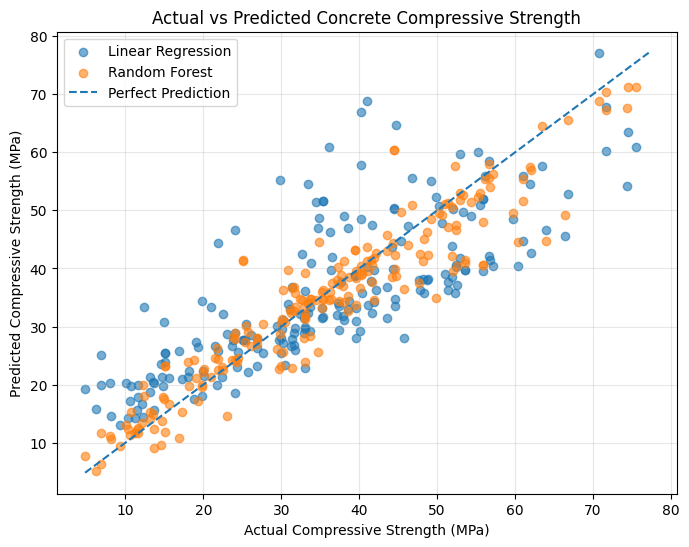

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.6,
    label="Linear Regression"
)

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6,
    label="Random Forest"
)

minimum = min(y_test.min(), linear_predictions.min(), rf_predictions.min())
maximum = max(y_test.max(), linear_predictions.max(), rf_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Compressive Strength (MPa)")
plt.ylabel("Predicted Compressive Strength (MPa)")
plt.title("Actual vs Predicted Concrete Compressive Strength")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Results and Discussion

Two supervised regression models, Linear Regression and Random Forest Regression, were trained to predict concrete compressive strength.

The dataset was divided into 80% training data and 20% test data. Both models were trained using the same training set and evaluated using the same test set.

The Linear Regression model achieved an MAE of **[insert value]**, an RMSE of **[insert value]**, and an R² score of **[insert value]**.

The Random Forest model achieved an MAE of **[insert value]**, an RMSE of **[insert value]**, and an R² score of **[insert value]**.

Based on the test results, **[insert the better-performing model]** performed better according to RMSE because it produced the lower value. The MAE and R² scores were also considered when comparing the models.

Linear Regression provides a relatively simple model, while Random Forest can capture more complex relationships between concrete ingredients, curing age, and compressive strength.

These results show how supervised machine learning can help estimate concrete strength. However, predictions should not replace required laboratory testing or engineering quality-control procedures without appropriate validation.

## Conclusion

This assignment demonstrated the main stages of supervised machine learning: identifying features and a target, splitting data into training and test sets, training two regression models, making predictions, and evaluating performance.

The comparison helped identify which of the two models performed better on the selected test data. Further testing on independent data would be useful before considering practical engineering applications.

## Dataset Source

UCI Machine Learning Repository: Concrete Compressive Strength Dataset  
https://archive.ics.uci.edu/dataset/165/concrete%2Bcompressive%2Bstrength